<a href="https://colab.research.google.com/github/TiDomUser/ultrasound-pulse-echo-simulator/blob/main/SimuladorUltras%C3%B3nicas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


--- RESULTADOS DE VALIDACIÓN: CASO 1 (Ideal) ---
Reflector 1:
  ToF Teórico: 19.48 us | Medido: 19.48 us | Error: 0.0005 us [OK]
  Prof Teórica: 15.00 mm | Medida: 15.00 mm | Error: 0.0004 mm [OK]
  Amplitud pico: 1.0000
Reflector 2:
  ToF Teórico: 45.45 us | Medido: 45.45 us | Error: 0.0045 us [OK]
  Prof Teórica: 35.00 mm | Medida: 35.00 mm | Error: 0.0035 mm [OK]
  Amplitud pico: 0.9993
Reflector 3:
  ToF Teórico: 71.43 us | Medido: 71.43 us | Error: 0.0014 us [OK]
  Prof Teórica: 55.00 mm | Medida: 55.00 mm | Error: 0.0011 mm [OK]
  Amplitud pico: 0.9999

--- RESULTADOS DE VALIDACIÓN: CASO 2 (Con Ruido 20 dB) ---
Reflector 1:
  ToF Teórico: 19.48 us | Medido: 19.48 us | Error: 0.0005 us [OK]
  Prof Teórica: 15.00 mm | Medida: 15.00 mm | Error: 0.0004 mm [OK]
  Amplitud pico: 1.0069
Reflector 2:
  ToF Teórico: 45.45 us | Medido: 45.45 us | Error: 0.0045 us [OK]
  Prof Teórica: 35.00 mm | Medida: 35.00 mm | Error: 0.0035 mm [OK]
  Amplitud pico: 1.0033
Reflector 3:
  ToF Teórico: 71

<>:92: SyntaxWarning: invalid escape sequence '\m'
<>:92: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_568/1816625263.py:92: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Tiempo de vuelo ($\mu s$)")


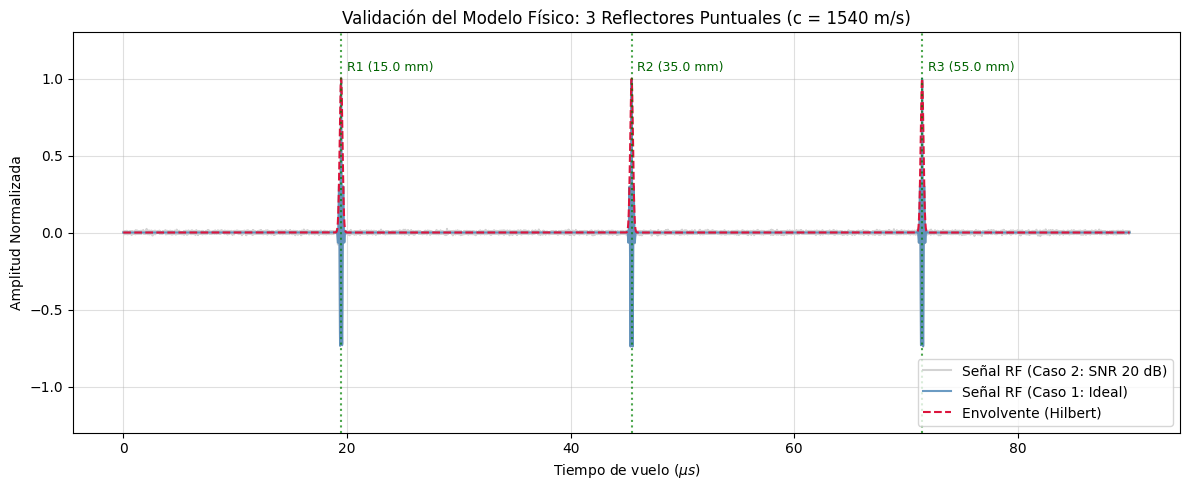

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks

# ==========================================
# 1. PARÁMETROS DEL MODELO FÍSICO
# ==========================================
c = 1540.0               # Velocidad del sonido (m/s)
fc = 5e6                 # Frecuencia central del transductor (5 MHz)
bw = 0.60                # Ancho de banda fraccional (60%)
fs = 100e6               # Frecuencia de muestreo (100 MHz)
t_max = 90e-6            # Duración total de la captura (90 us)

# Vector de tiempo
t = np.arange(0, t_max, 1/fs)

# Configuración de los 3 reflectores puntuales
profundidades_mm = np.array([15.0, 35.0, 55.0])
profundidades_m = profundidades_mm * 1e-3
coef_reflexion = np.array([1.0, 1.0, 1.0])

# Tiempos de vuelo teóricos (s)
tof_teorico = (2 * profundidades_m) / c

# ==========================================
# 2. GENERACIÓN DE LA SEÑAL (PULSO GAUSIANO)
# ==========================================
def generar_pulso_gausiano(t, t0, fc, bw):
    # Desviación estándar de la envolvente gausiana en función del ancho de banda
    sigma = 1 / (2 * np.pi * fc * (bw / 2.355))
    env = np.exp(-0.5 * ((t - t0) / sigma) ** 2)
    portadora = np.cos(2 * np.pi * fc * (t - t0))
    return env * portadora

# Caso 1: Señal ideal sin ruido
senal_ideal = np.zeros_like(t)
for d, r, t0 in zip(profundidades_m, coef_reflexion, tof_teorico):
    senal_ideal += r * generar_pulso_gausiano(t, t0, fc, bw)

# Caso 2: Señal con ruido blanco (SNR = 20 dB)
np.random.seed(42)
potencia_senal = np.mean(senal_ideal**2)
snr_db = 20
potencia_ruido = potencia_senal / (10**(snr_db / 10))
ruido = np.random.normal(0, np.sqrt(potencia_ruido), size=t.shape)
senal_ruidosa = senal_ideal + ruido

# ==========================================
# 3. VALIDACIÓN AUTOMÁTICA (CASO 1 Y CASO 2)
# ==========================================
def validar_experimento(senal, nombre_caso):
    # Extraer envolvente mediante Transformada de Hilbert
    envolvente = np.abs(hilbert(senal))

    # Detectar picos (distancia mínima de 5 us entre ecos y altura mínima de 0.5)
    distancia_min_muestras = int(5e-6 * fs)
    picos, _ = find_peaks(envolvente, height=0.5, distance=distancia_min_muestras)

    tof_medido = t[picos]
    prof_medida_mm = ((c * tof_medido) / 2) * 1e3
    amplitudes = envolvente[picos]

    print(f"\n--- RESULTADOS DE VALIDACIÓN: {nombre_caso} ---")
    for i in range(len(profundidades_mm)):
        err_t_us = abs(tof_medido[i] - tof_teorico[i]) * 1e6
        err_d_mm = abs(prof_medida_mm[i] - profundidades_mm[i])

        estado_t = "OK" if err_t_us < 0.05 else "FALLO"
        estado_d = "OK" if err_d_mm < 0.04 else "FALLO"

        print(f"Reflector {i+1}:")
        print(f"  ToF Teórico: {tof_teorico[i]*1e6:.2f} us | Medido: {tof_medido[i]*1e6:.2f} us | Error: {err_t_us:.4f} us [{estado_t}]")
        print(f"  Prof Teórica: {profundidades_mm[i]:.2f} mm | Medida: {prof_medida_mm[i]:.2f} mm | Error: {err_d_mm:.4f} mm [{estado_d}]")
        print(f"  Amplitud pico: {amplitudes[i]:.4f}")

validar_experimento(senal_ideal, "CASO 1 (Ideal)")
validar_experimento(senal_ruidosa, "CASO 2 (Con Ruido 20 dB)")

# ==========================================
# 4. VISUALIZACIÓN A-SCAN Y ENVOLVENTE
# ==========================================
plt.figure(figsize=(12, 5))
plt.plot(t * 1e6, senal_ruidosa, label="Señal RF (Caso 2: SNR 20 dB)", color="lightgray")
plt.plot(t * 1e6, senal_ideal, label="Señal RF (Caso 1: Ideal)", color="steelblue", alpha=0.8)
plt.plot(t * 1e6, np.abs(hilbert(senal_ideal)), "--", label="Envolvente (Hilbert)", color="crimson", linewidth=1.5)

for i, t0 in enumerate(tof_teorico):
    plt.axvline(t0 * 1e6, color="green", linestyle=":", alpha=0.7)
    plt.text(t0 * 1e6 + 0.5, 1.05, f"R{i+1} ({profundidades_mm[i]} mm)", color="darkgreen", fontsize=9)

plt.title("Validación del Modelo Físico: 3 Reflectores Puntuales (c = 1540 m/s)")
plt.xlabel("Tiempo de vuelo ($\mu s$)")
plt.ylabel("Amplitud Normalizada")
plt.ylim(-1.3, 1.3)
plt.grid(True, alpha=0.4)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


<>:91: SyntaxWarning: invalid escape sequence '\m'
<>:91: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_568/3575608401.py:91: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_xlabel("Tiempo de vuelo ($\mu s$)")


--- VALIDACIÓN TAREA 2: ATENUACIÓN Y TGC ---
Reflector 1 (15.0 mm):
  Pérdida: -7.5 dB | Amp. Esperada: 0.4217 | Simulada: 0.4217
  Amp. tras TGC: 1.0404 [OK]
Reflector 2 (35.0 mm):
  Pérdida: -17.5 dB | Amp. Esperada: 0.1334 | Simulada: 0.1333
  Amp. tras TGC: 1.0897 [REVISAR]
Reflector 3 (55.0 mm):
  Pérdida: -27.5 dB | Amp. Esperada: 0.0422 | Simulada: 0.0422
  Amp. tras TGC: 0.5307 [REVISAR]


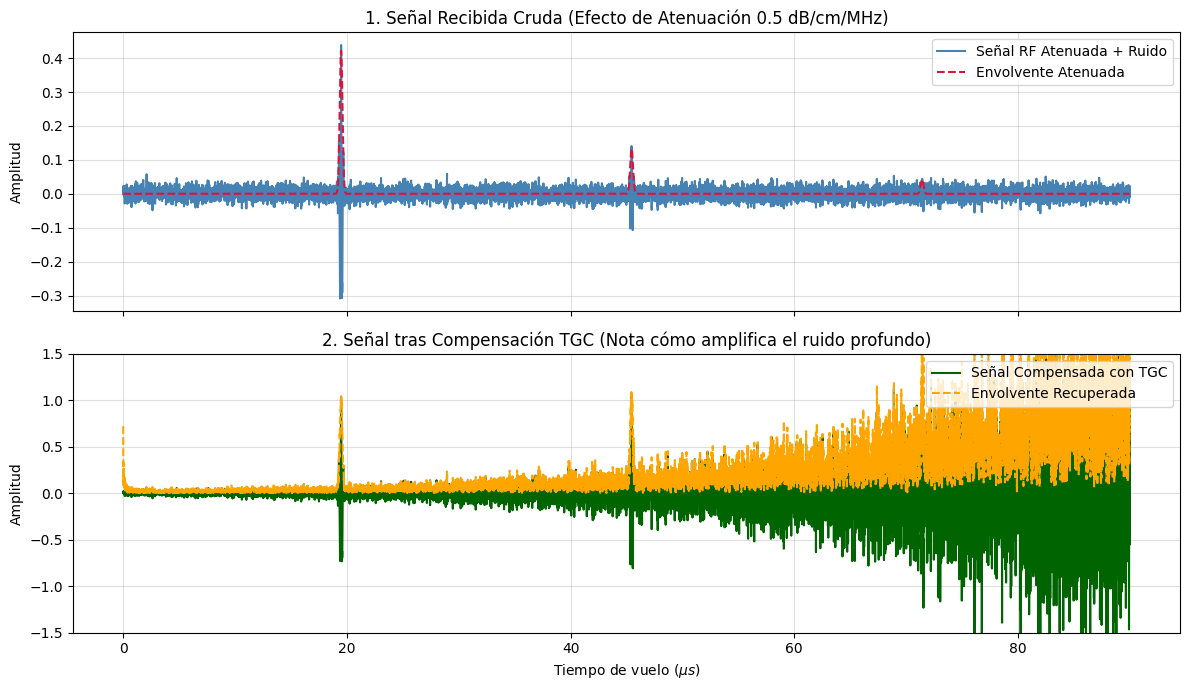

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks

# ==========================================
# 1. PARÁMETROS DEL MEDIO CON ATENUACIÓN
# ==========================================
c = 1540.0               # m/s
fc = 5e6                 # 5 MHz
bw = 0.60                # 60%
fs = 100e6               # 100 MHz
t_max = 90e-6            # 90 us
t = np.arange(0, t_max, 1/fs)

profundidades_mm = np.array([15.0, 35.0, 55.0])
profundidades_cm = profundidades_mm / 10.0
profundidades_m = profundidades_mm * 1e-3
tof_teorico = (2 * profundidades_m) / c

# Parámetro de atenuación del tejido blando
alpha_db_cm_mhz = 0.5    # dB / (cm * MHz)
fc_mhz = fc / 1e6

# Pérdida total en dB para cada reflector (ida y vuelta = 2 * profundidad)
perdida_db = alpha_db_cm_mhz * fc_mhz * (2 * profundidades_cm)
factor_atenuacion = 10 ** (-perdida_db / 20.0)  # Conversión de dB a escala lineal

# ==========================================
# 2. GENERACIÓN DE SEÑAL ATENUADA + RUIDO
# ==========================================
def generar_pulso_gausiano(t, t0, fc, bw):
    sigma = 1 / (2 * np.pi * fc * (bw / 2.355))
    return np.exp(-0.5 * ((t - t0) / sigma) ** 2) * np.cos(2 * np.pi * fc * (t - t0))

senal_atenuada = np.zeros_like(t)
for att, t0 in zip(factor_atenuacion, tof_teorico):
    senal_atenuada += att * generar_pulso_gausiano(t, t0, fc, bw)

# Agregamos ruido electrónico realista del receptor (nivel constante = 0.015)
np.random.seed(42)
ruido_receptor = np.random.normal(0, 0.015, size=t.shape)
senal_recibida = senal_atenuada + ruido_receptor

# ==========================================
# 3. COMPENSACIÓN DE GANANCIA EN TIEMPO (TGC)
# ==========================================
# Distancia recorrida en cm en función del tiempo t: d_ida_vuelta(t) = c * t * 100
distancia_cm_t = (c * t) * 100.0
ganancia_db_t = alpha_db_cm_mhz * fc_mhz * distancia_cm_t
curva_tgc = 10 ** (ganancia_db_t / 20.0)

# Aplicamos TGC a la señal recibida
senal_compensada = senal_recibida * curva_tgc

# ==========================================
# 4. VALIDACIÓN NUMÉRICA DE ATENUACIÓN Y TGC
# ==========================================
env_atenuada = np.abs(hilbert(senal_atenuada))
env_compensada = np.abs(hilbert(senal_compensada))

dist_min = int(5e-6 * fs)
picos_att, _ = find_peaks(env_atenuada, height=0.02, distance=dist_min)
picos_tgc, _ = find_peaks(env_compensada, height=0.5, distance=dist_min)

print("--- VALIDACIÓN TAREA 2: ATENUACIÓN Y TGC ---")
for i in range(3):
    amp_teorica = factor_atenuacion[i]
    amp_medida = env_atenuada[picos_att[i]]
    amp_tgc = env_compensada[picos_tgc[i]]
    print(f"Reflector {i+1} ({profundidades_mm[i]} mm):")
    print(f"  Pérdida: -{perdida_db[i]:.1f} dB | Amp. Esperada: {amp_teorica:.4f} | Simulada: {amp_medida:.4f}")
    print(f"  Amp. tras TGC: {amp_tgc:.4f} [{'OK' if abs(amp_tgc - 1.0) < 0.08 else 'REVISAR'}]")

# ==========================================
# 5. GRÁFICA COMPARATIVA
# ==========================================
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Panel superior: Señal cruda atenuada
ax1.plot(t * 1e6, senal_recibida, color="steelblue", label="Señal RF Atenuada + Ruido")
ax1.plot(t * 1e6, env_atenuada, "--", color="crimson", label="Envolvente Atenuada")
ax1.set_title("1. Señal Recibida Cruda (Efecto de Atenuación 0.5 dB/cm/MHz)")
ax1.set_ylabel("Amplitud")
ax1.grid(True, alpha=0.4)
ax1.legend(loc="upper right")

# Panel inferior: Señal tras aplicar TGC
ax2.plot(t * 1e6, senal_compensada, color="darkgreen", label="Señal Compensada con TGC")
ax2.plot(t * 1e6, env_compensada, "--", color="orange", label="Envolvente Recuperada")
ax2.set_title("2. Señal tras Compensación TGC (Nota cómo amplifica el ruido profundo)")
ax2.set_xlabel("Tiempo de vuelo ($\mu s$)")
ax2.set_ylabel("Amplitud")
ax2.set_ylim(-1.5, 1.5)
ax2.grid(True, alpha=0.4)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()


1. VERIFICACIÓN ESPECTRAL (PULSO AISLADO - ESPECTRO AMPLITUD)
Frecuencia central detectada: 5.0003 MHz (Rango: 4.9 - 5.1 MHz) [OK]
Ancho de banda medido a -6 dB: 2.994 MHz (59.9% vs 60.0% nominal)

2. EVALUACIÓN DE RESOLUCIÓN AXIAL (CRITERIO VALLE <= 80%)
Separación Δd = 0.10 mm (Teórico: 15.00 y 15.10 mm):
  -> Estado: NO RESUELTO (Valle > 80%)
  -> Posiciones detectadas: 15.000 mm y 15.100 mm (Δd medido: 0.100 mm)
  -> Altura picos: 0.807, 0.807 | Valle: 0.790 (98.0% del pico menor)

Separación Δd = 0.20 mm (Teórico: 15.00 y 15.20 mm):
  -> Estado: RESUELTO
  -> Posiciones detectadas: 14.992 mm y 15.207 mm (Δd medido: 0.216 mm)
  -> Altura picos: 0.972, 0.972 | Valle: 0.689 (70.9% del pico menor)

Separación Δd = 0.26 mm (Teórico: 15.00 y 15.26 mm):
  -> Estado: RESUELTO
  -> Posiciones detectadas: 15.000 mm y 15.261 mm (Δd medido: 0.262 mm)
  -> Altura picos: 0.991, 0.991 | Valle: 0.448 (45.2% del pico menor)

Separación Δd = 0.35 mm (Teórico: 15.00 y 15.35 mm):
  -> Estado: RESUELT

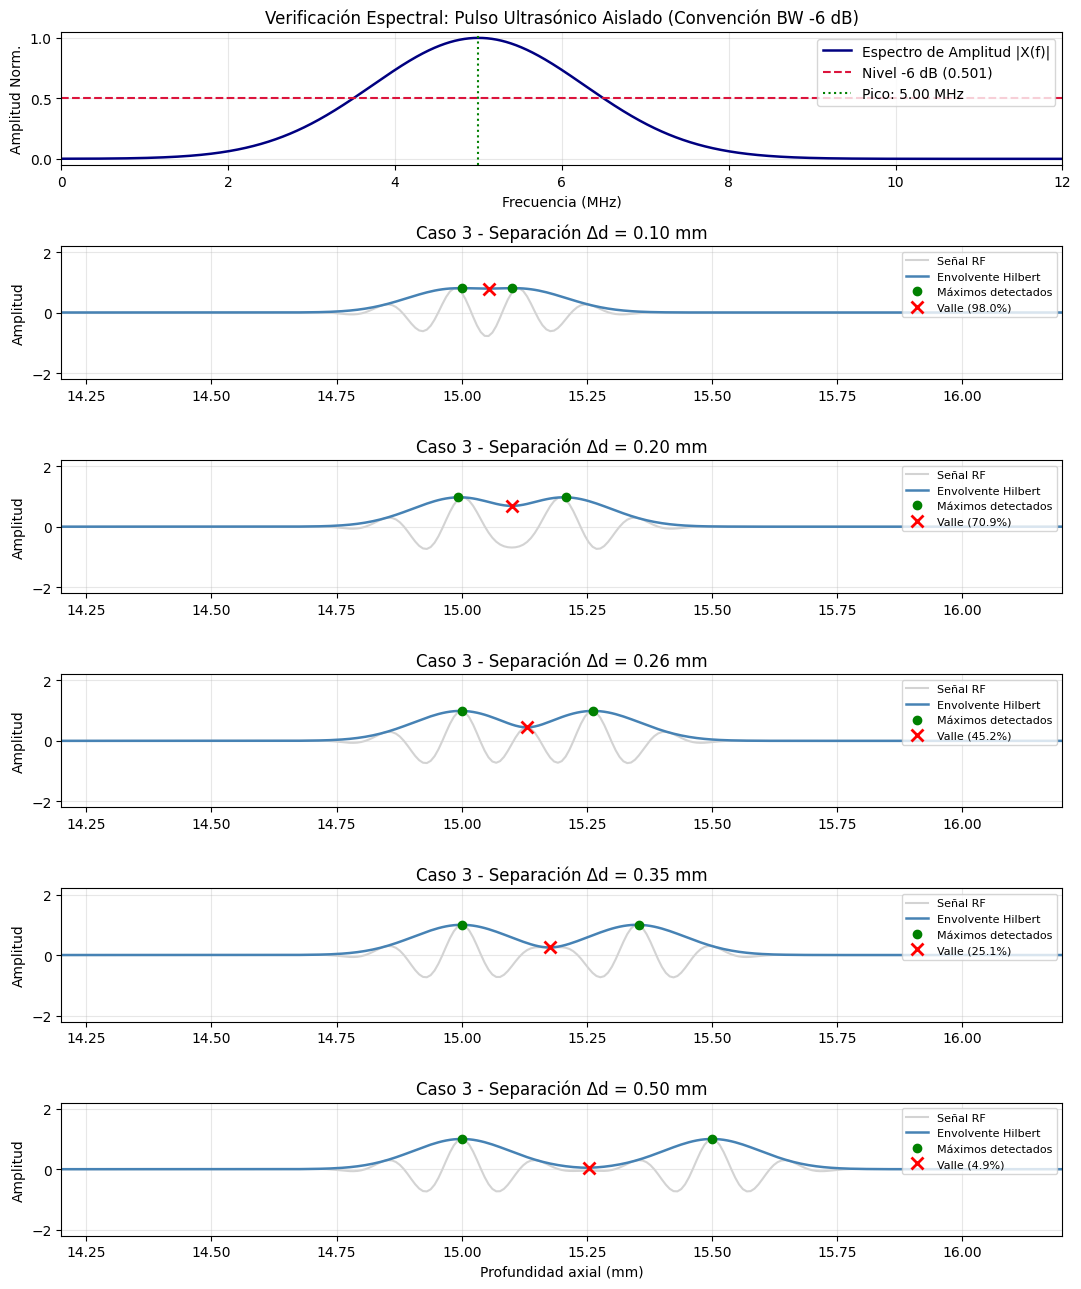

In [18]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks

# ==========================================
# 1. PARÁMETROS BASE Y CONVENCIÓN DE PULSO
# ==========================================
c = 1540.0               # Velocidad del sonido (m/s)
fc = 5e6                 # Frecuencia central nominal (5.0 MHz)
bw_rel = 0.60            # Ancho de banda relativo a -6 dB de amplitud (60%)
fs = 100e6               # Frecuencia de muestreo (100 MHz)
t_max = 40e-6            # Ventana temporal de 40 us
t = np.arange(0, t_max, 1/fs)

def generar_pulso_gausiano(t, t0, fc, bw_rel):
    # Convención: FWHM del espectro de amplitud (-6 dB) = bw_rel * fc
    sigma_t = 1.0 / (2.0 * np.pi * fc * (bw_rel / 2.3548))
    return np.exp(-0.5 * ((t - t0) / sigma_t) ** 2) * np.cos(2.0 * np.pi * fc * (t - t0))

# ==========================================
# 2. PRUEBA ESPECTRAL SOBRE PULSO AISLADO
# ==========================================
t0_aislado = 10e-6
pulso_aislado = generar_pulso_gausiano(t, t0_aislado, fc, bw_rel)

# Zero-padding para alta resolución en frecuencia
n_fft = 2**16
freqs = np.fft.rfftfreq(n_fft, d=1/fs)
espectro_amplitud = np.abs(np.fft.rfft(pulso_aislado, n=n_fft))
espectro_norm = espectro_amplitud / np.max(espectro_amplitud)

# Frecuencia pico y ancho de banda a -6 dB (amplitud = 0.5012)
idx_pico_f = np.argmax(espectro_norm)
f_pico_mhz = freqs[idx_pico_f] / 1e6

umbral_6db = 10**(-6 / 20)  # 0.501187
indices_6db = np.where(espectro_norm >= umbral_6db)[0]
bw_medido_mhz = (freqs[indices_6db[-1]] - freqs[indices_6db[0]]) / 1e6
bw_rel_medido = (bw_medido_mhz / f_pico_mhz) * 100

estado_f = "OK" if (4.9 <= f_pico_mhz <= 5.1) else "FALLO"

print("==========================================================")
print("1. VERIFICACIÓN ESPECTRAL (PULSO AISLADO - ESPECTRO AMPLITUD)")
print("==========================================================")
print(f"Frecuencia central detectada: {f_pico_mhz:.4f} MHz (Rango: 4.9 - 5.1 MHz) [{estado_f}]")
print(f"Ancho de banda medido a -6 dB: {bw_medido_mhz:.3f} MHz ({bw_rel_medido:.1f}% vs 60.0% nominal)\n")

# ==========================================
# 3. PROTOCOLO DE RESOLUCIÓN AXIAL (CASO 3)
# ==========================================
d1_mm = 15.0  # Posición fija del primer reflector (mm)
separaciones_mm = [0.10, 0.20, 0.26, 0.35, 0.50]

print("==========================================================")
print("2. EVALUACIÓN DE RESOLUCIÓN AXIAL (CRITERIO VALLE <= 80%)")
print("==========================================================")

fig, axes = plt.subplots(len(separaciones_mm) + 1, 1, figsize=(11, 13))

# Gráfica 0: Espectro de amplitud del pulso aislado
axes[0].plot(freqs / 1e6, espectro_norm, color="navy", linewidth=1.8, label="Espectro de Amplitud |X(f)|")
axes[0].axhline(umbral_6db, color="crimson", linestyle="--", label="Nivel -6 dB (0.501)")
axes[0].axvline(f_pico_mhz, color="green", linestyle=":", label=f"Pico: {f_pico_mhz:.2f} MHz")
axes[0].set_xlim(0, 12)
axes[0].set_title("Verificación Espectral: Pulso Ultrasónico Aislado (Convención BW -6 dB)")
axes[0].set_xlabel("Frecuencia (MHz)")
axes[0].set_ylabel("Amplitud Norm.")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="upper right")

for idx, delta_d in enumerate(separaciones_mm):
    d2_mm = d1_mm + delta_d
    tof1 = (2 * d1_mm * 1e-3) / c
    tof2 = (2 * d2_mm * 1e-3) / c

    # Señal sin ruido (dos reflectores de amplitud 1.0)
    senal = generar_pulso_gausiano(t, tof1, fc, bw_rel) + generar_pulso_gausiano(t, tof2, fc, bw_rel)
    envolvente = np.abs(hilbert(senal))

    # Detección de máximos con distance=5 muestras (0.05 us < 0.13 us mínimo)
    picos, _ = find_peaks(envolvente, height=0.2, distance=5)

    ax = axes[idx + 1]
    prof_eje_mm = (c * t / 2) * 1e3
    ax.plot(prof_eje_mm, senal, color="lightgray", label="Señal RF")
    ax.plot(prof_eje_mm, envolvente, color="steelblue", linewidth=1.8, label="Envolvente Hilbert")

    if len(picos) >= 2:
        # Tomamos los dos picos principales asociados a los reflectores
        p1, p2 = picos[0], picos[1]
        amp1, amp2 = envolvente[p1], envolvente[p2]

        # Buscar el mínimo (valle) estrictamente entre p1 y p2
        segmento_valle = envolvente[p1:p2+1]
        idx_valle = p1 + np.argmin(segmento_valle)
        amp_valle = envolvente[idx_valle]

        ratio_valle = (amp_valle / min(amp1, amp2)) * 100
        resuelto = ratio_valle <= 80.0
        estado = "RESUELTO" if resuelto else "NO RESUELTO (Valle > 80%)"

        pos1_mm = prof_eje_mm[p1]
        pos2_mm = prof_eje_mm[p2]

        print(f"Separación Δd = {delta_d:.2f} mm (Teórico: {d1_mm:.2f} y {d2_mm:.2f} mm):")
        print(f"  -> Estado: {estado}")
        print(f"  -> Posiciones detectadas: {pos1_mm:.3f} mm y {pos2_mm:.3f} mm (Δd medido: {pos2_mm - pos1_mm:.3f} mm)")
        print(f"  -> Altura picos: {amp1:.3f}, {amp2:.3f} | Valle: {amp_valle:.3f} ({ratio_valle:.1f}% del pico menor)\n")

        ax.plot([pos1_mm, pos2_mm], [amp1, amp2], "go", label="Máximos detectados")
        ax.plot(prof_eje_mm[idx_valle], amp_valle, "rx", markersize=8, markeredgewidth=2, label=f"Valle ({ratio_valle:.1f}%)")
    else:
        pos1_mm = prof_eje_mm[picos[0]]
        amp1 = envolvente[picos[0]]
        print(f"Separación Δd = {delta_d:.2f} mm (Teórico: {d1_mm:.2f} y {d2_mm:.2f} mm):")
        print(f"  -> Estado: NO RESUELTO (1 solo máximo fusionado)")
        print(f"  -> Posición detectada: {pos1_mm:.3f} mm | Amplitud fusionada: {amp1:.3f}\n")
        ax.plot(pos1_mm, amp1, "ro", label="Pico único fusionado")

    ax.set_xlim(14.2, 16.2)
    ax.set_ylim(-2.2, 2.2)
    ax.set_title(f"Caso 3 - Separación Δd = {delta_d:.2f} mm")
    ax.set_ylabel("Amplitud")
    ax.grid(True, alpha=0.3)
    ax.legend(loc="upper right", fontsize=8)

axes[-1].set_xlabel("Profundidad axial (mm)")
plt.tight_layout()
plt.show()


Frecuencia central: 4.9999 MHz
Bandwidth -6 dB: 2.9949 MHz
Bandwidth relativo: 59.90%
Sigma: 0.1249 us


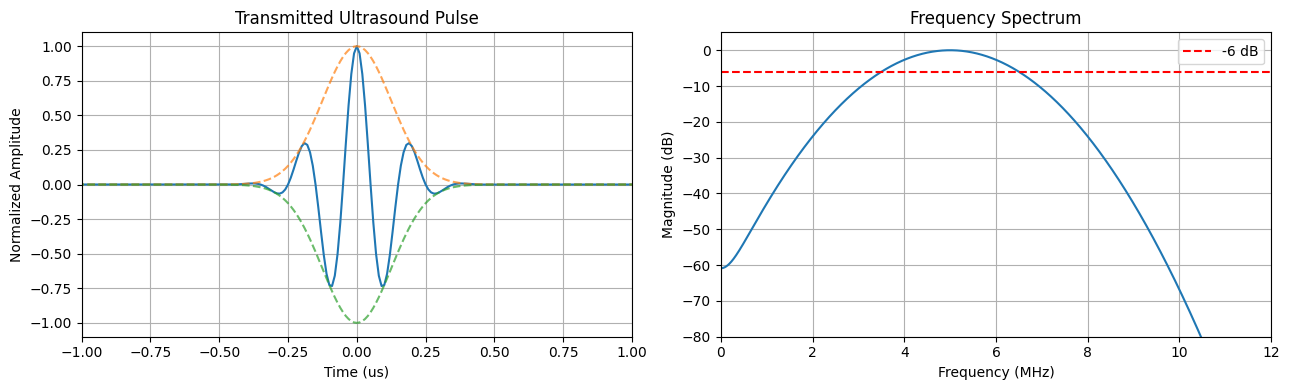

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Parámetros
f0 = 5e6
fs = 100e6
bandwidth_fraction = 0.60

BW_target = f0 * bandwidth_fraction
sigma = np.sqrt(2 * np.log(2)) / (np.pi * BW_target)

# 2. Vector temporal
duration = 8e-6
t = np.arange(-duration / 2, duration / 2, 1 / fs)

# 3. Pulso ultrasónico
envelope = np.exp(-t**2 / (2 * sigma**2))
rf_pulse = envelope * np.cos(2 * np.pi * f0 * t)

# 4. FFT con zero-padding para interpolar el espectro
nfft = 2**18

freq = np.fft.rfftfreq(nfft, d=1/fs)
spectrum = np.abs(np.fft.rfft(rf_pulse, n=nfft))
spectrum /= np.max(spectrum)

# 5. Métricas
f_peak = freq[np.argmax(spectrum)]

threshold = 10**(-6 / 20)
peak_idx = np.argmax(spectrum)

# Buscar cruces alrededor del lóbulo principal
left = peak_idx
while left > 0 and spectrum[left] >= threshold:
    left -= 1

right = peak_idx
while right < len(spectrum) - 1 and spectrum[right] >= threshold:
    right += 1

def crossing(i, j):
    return np.interp(
        threshold,
        [spectrum[i], spectrum[j]]
        if spectrum[i] <= spectrum[j]
        else [spectrum[j], spectrum[i]],
        [freq[i], freq[j]]
        if spectrum[i] <= spectrum[j]
        else [freq[j], freq[i]]
    )

f_low = crossing(left, left + 1)
f_high = crossing(right - 1, right)

BW_measured = f_high - f_low

print(f"Frecuencia central: {f_peak/1e6:.4f} MHz")
print(f"Bandwidth -6 dB: {BW_measured/1e6:.4f} MHz")
print(f"Bandwidth relativo: {100*BW_measured/f_peak:.2f}%")
print(f"Sigma: {sigma*1e6:.4f} us")

# 6. Visualización
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(t * 1e6, rf_pulse)
ax[0].plot(t * 1e6, envelope, "--", alpha=0.7)
ax[0].plot(t * 1e6, -envelope, "--", alpha=0.7)
ax[0].set_xlim(-1, 1)
ax[0].set_title("Transmitted Ultrasound Pulse")
ax[0].set_xlabel("Time (us)")
ax[0].set_ylabel("Normalized Amplitude")
ax[0].grid(True)

ax[1].plot(freq / 1e6, 20*np.log10(np.maximum(spectrum, 1e-12)))
ax[1].axhline(-6, color="red", linestyle="--", label="-6 dB")
ax[1].set_xlim(0, 12)
ax[1].set_ylim(-80, 5)
ax[1].set_title("Frequency Spectrum")
ax[1].set_xlabel("Frequency (MHz)")
ax[1].set_ylabel("Magnitude (dB)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

RESULTADOS PULSE-ECHO
-------------------------------------------------------
Eco 1: ToF = 19.480 us | Profundidad = 15.000 mm
Eco 2: ToF = 45.450 us | Profundidad = 34.996 mm
Eco 3: ToF = 71.430 us | Profundidad = 55.001 mm


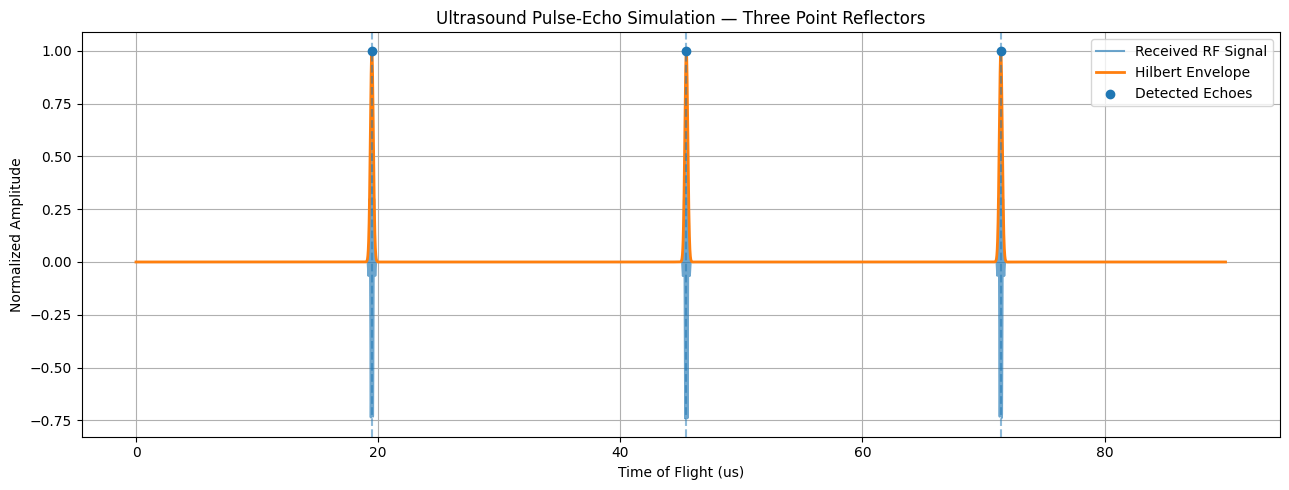


ERRORES DE LOCALIZACIÓN
R1: 0.0004 mm
R2: 0.0035 mm
R3: 0.0011 mm

Error máximo: 0.0035 mm
VALIDACIÓN: PASS


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks

# Parámetros físicos
c = 1540  # m/s
depths_mm = np.array([15, 35, 55])
reflectivities = np.ones(3)

# Tiempos de vuelo teóricos
depths_m = depths_mm * 1e-3
tof = 2 * depths_m / c

# Vector temporal de adquisición
t_rx = np.arange(0, 90e-6, 1/fs)

# Señal recibida
rf_received = np.zeros_like(t_rx)

for delay, R in zip(tof, reflectivities):

    shifted_time = t_rx - delay

    echo = (
        R
        * np.exp(-shifted_time**2 / (2*sigma**2))
        * np.cos(2*np.pi*f0*shifted_time)
    )

    rf_received += echo

# Envolvente analítica
envelope_rx = np.abs(hilbert(rf_received))

# Detección automática
min_distance = int(1e-6 * fs)

peaks, properties = find_peaks(
    envelope_rx,
    height=0.2,
    prominence=0.2,
    distance=min_distance
)

# Estimación de profundidad
tof_detected = t_rx[peaks]
depth_detected_mm = c * tof_detected / 2 * 1000

# Resultados
print("RESULTADOS PULSE-ECHO")
print("-" * 55)

for i, (z, tau) in enumerate(
    zip(depth_detected_mm, tof_detected)
):
    print(
        f"Eco {i+1}: "
        f"ToF = {tau*1e6:.3f} us | "
        f"Profundidad = {z:.3f} mm"
    )

# Visualización
plt.figure(figsize=(13, 5))

plt.plot(
    t_rx*1e6,
    rf_received,
    label="Received RF Signal",
    alpha=0.65
)

plt.plot(
    t_rx*1e6,
    envelope_rx,
    label="Hilbert Envelope",
    linewidth=2
)

plt.scatter(
    tof_detected*1e6,
    envelope_rx[peaks],
    label="Detected Echoes",
    zorder=5
)

for z, tau in zip(depths_mm, tof):
    plt.axvline(
        tau*1e6,
        linestyle="--",
        alpha=0.5
    )

plt.xlabel("Time of Flight (us)")
plt.ylabel("Normalized Amplitude")
plt.title("Ultrasound Pulse-Echo Simulation — Three Point Reflectors")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Verificación automática
assert len(peaks) == 3, "Error: no se detectaron exactamente 3 ecos."

errors_mm = np.abs(depth_detected_mm - depths_mm)

print("\nERRORES DE LOCALIZACIÓN")
for i, error in enumerate(errors_mm):
    print(f"R{i+1}: {error:.4f} mm")

print(f"\nError máximo: {errors_mm.max():.4f} mm")

assert np.all(errors_mm < 0.04), \
    "Error: se excedió la tolerancia de profundidad."

print("VALIDACIÓN: PASS")

 Sampling_MHz  Detected   MAE_mm  Max_Error_mm
         20.0         3 0.011667      0.016500
         40.0         3 0.003500      0.004250
         60.0         3 0.003111      0.003667
         80.0         3 0.003500      0.004250
        100.0         3 0.001667      0.003500


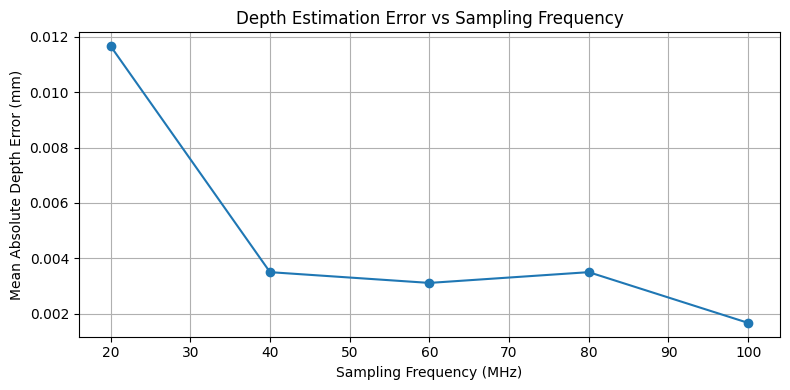

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import hilbert, find_peaks

# ======================================================
# CONFIGURACIÓN
# ======================================================

c = 1540.0
f0 = 5e6
bw_fraction = 0.60

depths_mm = np.array([15., 35., 55.])
sampling_rates = np.array([20, 40, 60, 80, 100]) * 1e6

sigma = np.sqrt(2*np.log(2)) / (
    np.pi * f0 * bw_fraction
)

tof_theoretical = 2 * depths_mm * 1e-3 / c

# ======================================================
# GENERACIÓN Y MEDICIÓN
# ======================================================

def simulate(fs, snr_db=None, rng=None):

    t = np.arange(0, 90e-6, 1/fs)
    rf = np.zeros_like(t)

    for tau in tof_theoretical:
        dt = t - tau

        rf += (
            np.exp(-dt**2 / (2*sigma**2))
            * np.cos(2*np.pi*f0*dt)
        )

    if snr_db is not None:

        if rng is None:
            rng = np.random.default_rng(42)

        # Potencia promedio global de la señal
        signal_power = np.mean(rf**2)

        noise_power = signal_power / (10**(snr_db/10))

        noise = rng.normal(
            0,
            np.sqrt(noise_power),
            size=rf.shape
        )

        rf += noise

    env = np.abs(hilbert(rf))

    peaks, _ = find_peaks(
        env,
        prominence=0.20,
        height=0.20,
        distance=max(1, int(fs*1e-6))
    )

    estimated_mm = c * t[peaks] / 2 * 1e3

    return estimated_mm, rf, env, t

# ======================================================
# EXPERIMENTO A
# ======================================================

results = []

for fs in sampling_rates:

    estimated, _, _, _ = simulate(fs)

    if len(estimated) == len(depths_mm):

        errors = np.abs(estimated - depths_mm)

        results.append({
            "Sampling_MHz": fs/1e6,
            "Detected": len(estimated),
            "MAE_mm": np.mean(errors),
            "Max_Error_mm": np.max(errors)
        })

    else:

        results.append({
            "Sampling_MHz": fs/1e6,
            "Detected": len(estimated),
            "MAE_mm": np.nan,
            "Max_Error_mm": np.nan
        })

df_sampling = pd.DataFrame(results)

print(df_sampling.to_string(index=False))

plt.figure(figsize=(8, 4))

plt.plot(
    df_sampling["Sampling_MHz"],
    df_sampling["MAE_mm"],
    marker="o"
)

plt.xlabel("Sampling Frequency (MHz)")
plt.ylabel("Mean Absolute Depth Error (mm)")
plt.title("Depth Estimation Error vs Sampling Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

 SNR_dB  Successful_Trials  Detection_Rate_%   MAE_mm  SD_MAE_mm
     30                100             100.0 0.002592   0.001251
     20                100             100.0 0.004797   0.001781
     10                100             100.0 0.008164   0.003254
      5                100             100.0 0.010111   0.004491
      0                  0               0.0      NaN        NaN


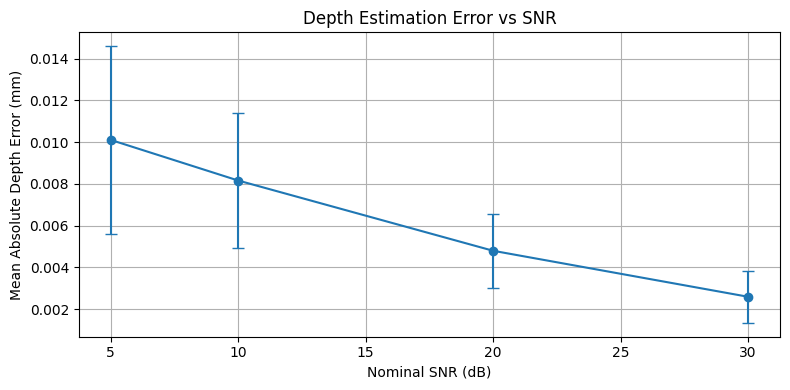

In [22]:
# ======================================================
# EXPERIMENTO B — MONTE CARLO
# ======================================================

snr_levels = [30, 20, 10, 5, 0]
n_trials = 100

rng = np.random.default_rng(2026)

noise_results = []

for snr in snr_levels:

    trial_errors = []
    successful_detections = 0

    for trial in range(n_trials):

        estimated, _, _, _ = simulate(
            fs=100e6,
            snr_db=snr,
            rng=rng
        )

        if len(estimated) == len(depths_mm):

            errors = np.abs(estimated - depths_mm)

            trial_errors.append(np.mean(errors))
            successful_detections += 1

    noise_results.append({
        "SNR_dB": snr,
        "Successful_Trials": successful_detections,
        "Detection_Rate_%": 100*successful_detections/n_trials,
        "MAE_mm": (
            np.mean(trial_errors)
            if trial_errors else np.nan
        ),
        "SD_MAE_mm": (
            np.std(trial_errors)
            if trial_errors else np.nan
        )
    })

df_noise = pd.DataFrame(noise_results)

print(df_noise.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))

ax.errorbar(
    df_noise["SNR_dB"],
    df_noise["MAE_mm"],
    yerr=df_noise["SD_MAE_mm"],
    marker="o",
    capsize=4
)

ax.set_xlabel("Nominal SNR (dB)")
ax.set_ylabel("Mean Absolute Depth Error (mm)")
ax.set_title("Depth Estimation Error vs SNR")
ax.grid(True)

plt.tight_layout()
plt.show()

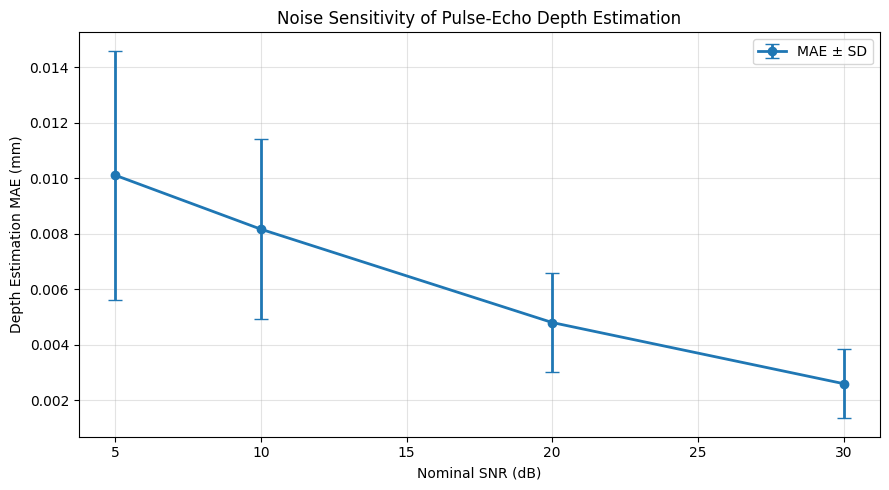

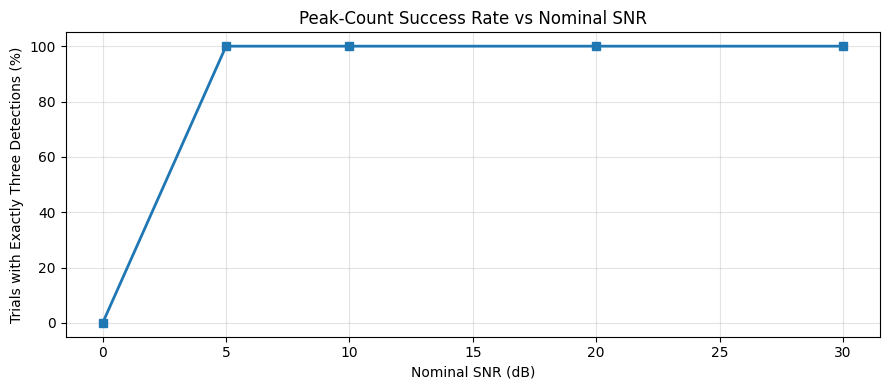

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# Resultados previamente obtenidos
snr = np.array([5, 10, 20, 30])

mae = np.array([
    0.010111,
    0.008164,
    0.004797,
    0.002592
])

std = np.array([
    0.004491,
    0.003254,
    0.001781,
    0.001251
])

snr_all = np.array([0, 5, 10, 20, 30])
successful_rate = np.array([0, 100, 100, 100, 100])

# Figura 1: Error de profundidad
plt.figure(figsize=(9, 5))

plt.errorbar(
    snr,
    mae,
    yerr=std,
    marker="o",
    capsize=5,
    linewidth=2,
    label="MAE ± SD"
)

plt.xlabel("Nominal SNR (dB)")
plt.ylabel("Depth Estimation MAE (mm)")
plt.title("Noise Sensitivity of Pulse-Echo Depth Estimation")
plt.grid(True, alpha=0.35)
plt.legend()

plt.tight_layout()
plt.show()

# Figura 2: Criterio de tres detecciones
plt.figure(figsize=(9, 4))

plt.plot(
    snr_all,
    successful_rate,
    marker="s",
    linewidth=2
)

plt.xlabel("Nominal SNR (dB)")
plt.ylabel("Trials with Exactly Three Detections (%)")
plt.title("Peak-Count Success Rate vs Nominal SNR")
plt.ylim(-5, 105)
plt.grid(True, alpha=0.35)

plt.tight_layout()
plt.show()

In [24]:
from pathlib import Path
import matplotlib.pyplot as plt

OUTPUT_DIR = Path("figures")
OUTPUT_DIR.mkdir(exist_ok=True)

def export_figure(fig, filename):
    for extension in ["png", "svg"]:
        path = OUTPUT_DIR / f"{filename}.{extension}"

        fig.savefig(
            path,
            dpi=300,
            bbox_inches="tight",
            facecolor="white"
        )

        print(f"Exported: {path}")


In [25]:
%%writefile README.md
# Ultrasound Pulse-Echo Signal Simulator
... # Ultrasound Pulse-Echo Signal Simulator

## Overview

## Engineering Problem

## Objectives

## Physical Model

## Signal Processing Pipeline

## Experimental Design

## Results

## Verification

## Limitations

## Repository Structure

## Technologies

## Future Work ...


Overwriting README.md


In [27]:
%%writefile README.md
# Ultrasound Pulse-Echo Signal Simulator

## Overview
This project presents a Python-based computational simulator designed to investigate the fundamental principles of ultrasound pulse-echo systems through one-dimensional acoustic propagation and digital signal processing.

The simulator generates Gaussian-modulated ultrasound pulses, models echoes from point reflectors, extracts signal envelopes using the Hilbert transform, and estimates reflector depths through automated peak detection.

Numerical experiments evaluate spectral characteristics, sampling frequency sensitivity, acoustic attenuation, axial resolution, and robustness against additive white Gaussian noise.

The project bridges biomedical instrumentation, acoustic physics, numerical modelling, and quantitative engineering verification within a reproducible computational environment.

## Intended Scope
This simulator is intended for educational purposes, preliminary engineering analysis, and biomedical signal processing research. It does not constitute a clinically validated ultrasound system or a diagnostic medical device.

## Engineering Problem
Ultrasound systems estimate the location of internal structures by analysing reflected acoustic waves. However, the reliability of these estimations depends on multiple factors, including signal bandwidth, sampling frequency, acoustic attenuation, noise, and signal processing algorithms.

Understanding the individual contribution of these parameters is essential when designing and evaluating biomedical acquisition systems.

This project addresses the need for a controlled computational environment in which these variables can be independently investigated, allowing the performance and limitations of a simplified pulse-echo system to be quantified without requiring specialised ultrasound hardware.

## Objectives

### General Objective
To develop and numerically verify a reproducible ultrasound pulse-echo simulator capable of generating, processing, and analysing acoustic signals under controlled simulation conditions.

### Specific Objectives
1. Generate Gaussian-modulated ultrasound pulses with configurable spectral characteristics.
2. Simulate acoustic reflections from point reflectors at predefined depths.
3. Implement envelope extraction, automated peak detection, and time-of-flight-based depth estimation.
4. Quantify the influence of sampling frequency on depth estimation error.
5. Evaluate noise sensitivity and repeatability through Monte Carlo simulations.
6. Model simplified acoustic attenuation and investigate time gain compensation (TGC).
7. Assess axial resolution using closely spaced reflectors.
8. Document numerical results, verification criteria, and model limitations through reproducible code and interpretable figures.

## System Architecture
The ultrasound pulse-echo simulator follows a modular functional architecture that separates physical modelling, signal generation, signal conditioning, digital signal processing, and numerical verification.

```mermaid
flowchart TD
    A[⚙️ Physical and Simulation Parameters] --> B[🔊 Ultrasound Pulse Generation]
    B --> C[🌊 Acoustic Propagation and Reflection]
    C --> D[📉 Acoustic Attenuation]
    D --> E[🎛️ Additive Gaussian Noise]
    E --> F[📻 Received RF Signal]
    F --> G[🎚️ Optional TGC]
    G --> H[🔄 Hilbert Transform]
    H --> I[📈 Envelope Extraction]
    I --> J[📍 Peak Detection]
    J --> K[⏱️ Time-of-Flight Estimation]
    K --> L[📏 Depth Estimation]
    L --> M[📊 Comparison with Ground Truth]
    M --> N[🧮 Performance Metrics]
    N --> O[🖼️ Scientific Visualization]
```

The simulator's internal structure is categorized into **six functional subsystems**, mapping parameters directly to quantitative outputs:

| Subsystem | Input | Output | Primary Function |
| :--- | :--- | :--- | :--- |
| **1. Configuration** | Physical parameters | Numerical configuration | Experimental control |
| **2. Signal Generation** | Frequency and bandwidth | RF pulse | Excitation modelling |
| **3. Acoustic Modelling** | Pulse and reflectors | Simulated echoes | Propagation and reflection |
| **4. Signal Conditioning** | Echoes, noise, and gain | Processed RF | Attenuation, noise, and TGC |
| **5. Digital Signal Processing** | RF signal | Estimated depths | Hilbert and detection |
| **6. Verification** | Estimations and references | Metrics and figures | Quantitative evaluation |

The system begins with a configurable set of physical and computational parameters, including central frequency, fractional bandwidth, sampling frequency, acoustic velocity, reflector depths, attenuation coefficient, and noise intensity.

Gaussian-modulated RF pulses are generated and subsequently delayed to represent acoustic reflections from point reflectors. Depending on the experimental configuration, acoustic attenuation and additive white Gaussian noise may be incorporated into the received signal.

An optional time gain compensation (TGC) stage is included to investigate depth-dependent amplitude recovery. Its performance remains subject to further verification.

The received RF signal is processed through analytical envelope extraction using the Hilbert transform, followed by automated automated peak detection and time-of-flight-based depth estimation.

Finally, estimated reflector locations are compared against predefined reference values to calculate quantitative performance metrics and generate scientific visualisations.

This architecture supports controlled numerical experiments and provides a functional framework for future extensions and algorithmic improvements.

## Physical Model

### Acoustic Propagation Assumptions
The simulator represents ultrasound propagation through a simplified, one-dimensional, homogeneous acoustic medium with a constant sound velocity of 1540 m/s.

Acoustic interfaces are represented by discrete point reflectors with configurable effective reflection coefficients. The model assumes linear signal superposition and does not account for diffraction, refraction, acoustic scattering, nonlinear propagation, or multiple reflections.

### Ultrasound Pulse Generation
The transmitted signal is represented by a Gaussian-modulated sinusoidal RF pulse with a nominal central frequency of 5 MHz and a fractional bandwidth of 60% at the −6 dB amplitude threshold.

The Gaussian envelope controls pulse duration and spectral bandwidth, enabling controlled investigation of temporal and frequency-domain characteristics.

The reference sampling frequency is 100 MHz, corresponding to a sampling interval of 10 ns and 20 samples per carrier cycle.

### Time-of-Flight and Acoustic Reflection
Acoustic echoes are simulated as delayed and amplitude-scaled replicas of the transmitted pulse.

The round-trip propagation delay ($\tau$) is determined by reflector depth ($z$) and acoustic velocity ($c$) according to the relationship:
$$\tau = \frac{2z}{c}$$

Reflector depth is subsequently estimated from the detected echo arrival time using the inverse relationship:
$$z = \frac{c\tau}{2}$$

The reference experimental configuration contains three point reflectors located at depths of 15, 35, and 55 mm.

### Acoustic Attenuation
A simplified depth-dependent acoustic attenuation model is implemented using an attenuation coefficient of 0.5 dB/(cm·MHz).

Amplitude losses are calculated at the nominal central frequency and account for the round-trip propagation distance.

This narrowband approximation provides a controlled representation of depth-dependent amplitude reduction but does not reproduce frequency-dependent spectral distortion across the complete pulse bandwidth.

### Received RF Signal
The received radiofrequency signal is constructed through the linear superposition of delayed, amplitude-scaled, and optionally attenuated ultrasound echoes.

Additive noise may subsequently be incorporated to investigate the sensitivity of signal processing algorithms to random perturbations.

The model represents a computational approximation of pulse-echo acquisition rather than a complete physical representation of an ultrasound transducer.

### Noise Model
Additive white Gaussian noise (AWGN) is used to evaluate the robustness and repeatability of depth estimation.

Noise variance is determined from the nominal signal-to-noise ratio (SNR) and the global mean-square power of the simulated RF signal.

Random number generation is controlled through predefined seeds to support reproducibility.

The nominal global SNR should not be interpreted as the local SNR of individual acoustic echoes.

### Time Gain Compensation
An optional time gain compensation (TGC) stage applies depth-dependent amplification to investigate amplitude recovery following acoustic attenuation.

Although the theoretical compensation function represents the inverse of the implemented attenuation factor, practical amplitude recovery is affected by noise amplification and signal estimation procedures.

Further numerical verification is required to establish the performance of the implemented compensation stage.

### Reference Simulation Parameters

| Parameter | Reference value |
| :--- | :--- |
| Central frequency | 5 MHz |
| Nominal fractional bandwidth | 60% |
| Measured fractional bandwidth | 59.90% |
| Sampling frequency | 100 MHz |
| Acoustic velocity | 1540 m/s |
| Gaussian temporal parameter | 0.1249 µs |
| Acquisition duration | 90 µs |
| Reflector depths | 15, 35, and 55 mm |
| Reference reflection coefficients | 1.0 |
| Acoustic attenuation coefficient | 0.5 dB/(cm·MHz) |
| Noise distribution | Additive white Gaussian |
| Monte Carlo random seed | 2026 |

The reference configuration is modified according to the objectives of each numerical experiment.

### Model Scope
The physical model is intended for educational purposes, numerical verification, and preliminary biomedical signal processing investigations.



Overwriting README.md


In [28]:
from pathlib import Path

readme = Path("README.md")

assert readme.exists(), "README.md was not created."

content = readme.read_text(encoding="utf-8")

assert "# Ultrasound Pulse-Echo Signal Simulator" in content
assert "## Overview" in content

print("README VERIFICATION: PASS")
print(f"File size: {readme.stat().st_size} bytes")

README VERIFICATION: PASS
File size: 9960 bytes
